
# Mobile Network Performance and Outage Impact Analysis with Future Outage Prediction
## Final Exploratory Data Analysis (EDA)

**Project:** Mobile Network Availability and Impact Monitoring Using Python and Machine Learning

### EDA purpose
This notebook is the **EDA stage only**. It is designed to understand the structure, quality, KPI behavior, outage patterns, and relationships in the two current project datasets before feature engineering and machine-learning modeling.

### Current project structure
- **Dataset 1 — Site/Cell Information:** network structure, geography, technology, and neighboring-cell relationships.
- **Dataset 2 — Network KPI + Outage Data:** regular KPI measurements plus `OUTAGE` and `RECOVERY` event records.
- Dataset 1 and Dataset 2 are related using **`Site_ID + Cell_ID`**.
- Regular Dataset 2 KPI records are recorded **every 3 hours**.
- `OUTAGE` and `RECOVERY` records are event records at their actual timestamps.
- KPI fields may be `NaN` in event rows because those rows record events rather than regular KPI measurements.
- `Outage_Next_12h` is **not created in this EDA notebook**. It will be created later from future outage events during feature preparation.



## 0. Imports and Configuration

Because Dataset 2 is large, the notebook uses **streaming/chunked processing** for full-file summaries and a bounded sample for plots. This avoids loading the whole merged dataset into RAM unnecessarily.


In [1]:

from pathlib import Path
import csv
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# -----------------------------
# File paths
# -----------------------------
DATASET_2_FOLDER = Path(
    r"C:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_2_Cell_KPI_Outage"
)

DATASET_1_FILE = Path(
    r"C:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_1_Cell_Information.csv"
)

DATASET_2_MERGED_FILE = (
    DATASET_2_FOLDER / "Dataset_2_Merged.csv"
)

# -----------------------------
# Processing settings
# -----------------------------
CSV_CHUNK_SIZE = 100_000
PLOT_SAMPLE_SIZE = 100_000

print("Dataset 1:", DATASET_1_FILE)
print("Dataset 2:", DATASET_2_MERGED_FILE)

print("\nDataset 1 exists:", DATASET_1_FILE.exists())
print("Dataset 2 exists:", DATASET_2_MERGED_FILE.exists())


Dataset 1: C:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_1_Cell_Information.csv
Dataset 2: C:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_2_Cell_KPI_Outage\Dataset_2_Merged.csv

Dataset 1 exists: True
Dataset 2 exists: True


## 1. Dataset 1 — Site/Cell Information EDA

In [2]:

# Load Dataset 1
df1 = pd.read_csv(DATASET_1_FILE)

print("Dataset 1 shape:", df1.shape)
display(df1.head())


Dataset 1 shape: (22900, 8)


,Site_ID,Site_Name,Cell_ID,Cell_Name,Technology,Region,District,Neighbor_Cell_ID
0,UG-MBR-1752,MBR_MBARARA_1752,UG-MBR-1752-S02,MBR_MBARARA_1752_S02_UMTS2100,3G,Western,Mbarara,"UG-MBR-0212-S03,UG-MBR-1255-S03,UG-MBR-1274-S0..."
1,UG-HOI-2650,HOI_KIGYAMBA_2650,UG-HOI-2650-S03,HOI_KIGYAMBA_2650_S03_L26,4G,Western,Hoima,"UG-HOI-0172-S02,UG-HOI-0858-S04,UG-HOI-0869-S0..."
2,UG-MSK-4576,MSK_KIMAANYI_4576,UG-MSK-4576-S02,MSK_KIMAANYI_4576_S02_UMTS2100,3G,Western,Masaka,"UG-MSK-0311-S02,UG-MSK-1067-S02,UG-MSK-1712-S0..."
3,UG-WAK-0925,WAK_KAKIRI_0925,UG-WAK-0925-S03,WAK_KAKIRI_0925_S03_L26,4G,Central,Wakiso,"UG-WAK-0177-S01,UG-WAK-0925-S02,UG-WAK-0925-S0..."
4,UG-MBA-0651,MBA_MBALE_0651,UG-MBA-0651-S03,MBA_MBALE_0651_S03_L18,4G,Eastern,Mbale,"UG-FTP-0647-S02,UG-MBA-0651-S02,UG-MBA-0651-S0..."


In [3]:

# Column names and data types
print("Columns:")
print(df1.columns.tolist())

print("\nData types:")
display(df1.dtypes.to_frame("Data_Type"))


Columns:
['Site_ID', 'Site_Name', 'Cell_ID', 'Cell_Name', 'Technology', 'Region', 'District', 'Neighbor_Cell_ID']

Data types:


,Data_Type
Site_ID,str
Site_Name,str
Cell_ID,str
Cell_Name,str
Technology,str
Region,str
District,str
Neighbor_Cell_ID,str


In [4]:

# Missing values and duplicates
missing1 = df1.isna().sum().sort_values(ascending=False)

print("Missing values:")
display(missing1.to_frame("Missing_Count"))

print("Duplicate rows:", df1.duplicated().sum())


Missing values:


,Missing_Count
Site_ID,0
Site_Name,0
Cell_ID,0
Cell_Name,0
Technology,0
Region,0
District,0
Neighbor_Cell_ID,0


Duplicate rows: 0


In [5]:

# Network size and technology distribution
print("Unique sites:", df1["Site_ID"].nunique())
print("Unique cells:", df1["Cell_ID"].nunique())

print("\nTechnology distribution:")
display(df1["Technology"].value_counts(dropna=False).to_frame("Cell_Count"))

print("\nRegion distribution:")
display(df1["Region"].value_counts(dropna=False).to_frame("Cell_Count"))

print("\nDistrict distribution:")
display(
    df1["District"]
    .value_counts(dropna=False)
    .head(30)
    .to_frame("Cell_Count")
)


Unique sites: 6000
Unique cells: 22900

Technology distribution:


,Cell_Count
Technology,
3G,6000
4G,6000
2G,6000
5G,4900



Region distribution:


,Cell_Count
Region,
Eastern,6520
Northern,5762
Western,5705
Central,4913



District distribution:


,Cell_Count
District,
Arua,831
Mpigi,827
Nebbi,826
Yumbe,825
Kitgum,823
Moyo,823
Mubende,822
Fort Portal,822
Soroti,821


In [6]:

# Cells per site
cells_per_site = df1.groupby("Site_ID")["Cell_ID"].nunique()

print("Cells per site — descriptive statistics:")
display(cells_per_site.describe().to_frame("Cells_Per_Site"))

print("Cells per site — frequency:")
display(
    cells_per_site
    .value_counts()
    .sort_index()
    .to_frame("Number_of_Sites")
)


Cells per site — descriptive statistics:


,Cells_Per_Site
count,6000.000000
mean,3.816667
std,0.386972
min,3.000000
25%,4.000000
50%,4.000000
75%,4.000000
max,4.000000


Cells per site — frequency:


,Number_of_Sites
Cell_ID,
3,1100
4,4900


Neighbor-count statistics:


,Neighbor_Count
count,22900.000000
mean,10.290480
std,1.847731
min,3.000000
25%,9.000000
50%,11.000000
75%,12.000000
max,12.000000


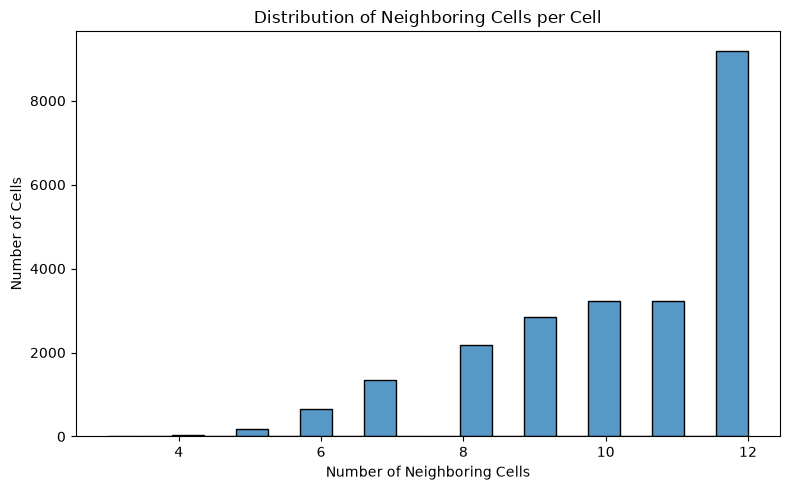

In [7]:

# Neighbor count
def count_neighbors(value):
    if pd.isna(value) or str(value).strip() == "":
        return 0
    return len([x for x in str(value).split(",") if x.strip()])

df1["Neighbor_Count"] = df1["Neighbor_Cell_ID"].apply(count_neighbors)

print("Neighbor-count statistics:")
display(df1["Neighbor_Count"].describe().to_frame("Neighbor_Count"))

plt.figure(figsize=(8, 5))
sns.histplot(df1["Neighbor_Count"], bins=20)
plt.title("Distribution of Neighboring Cells per Cell")
plt.xlabel("Number of Neighboring Cells")
plt.ylabel("Number of Cells")
plt.tight_layout()
plt.show()



## 2. Dataset 2 — File and Schema Validation

Dataset 2 is a very large merged CSV. Before performing EDA, the notebook checks its header and reads a small sample to confirm the schema.


In [8]:

# Read a small sample only
sample_df2 = pd.read_csv(
    DATASET_2_MERGED_FILE,
    nrows=10_000,
    low_memory=False
)

print("Dataset 2 sample shape:", sample_df2.shape)
display(sample_df2.head())

print("\nDataset 2 columns:")
print(sample_df2.columns.tolist())


Dataset 2 sample shape: (10000, 16)


,Timestamp,Site_ID,Cell_ID,Record_Type,Status,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count,Cell_Down_Time,Cell_Up_Time
0,2024-01-01,UG-BSH-1275,UG-BSH-1275-S01,KPI,UP,0.714,25.0,0.439,159.147,0.380,10.440,20.139,0.0,0,NaN,NaN
1,2024-01-01,UG-MPG-1384,UG-MPG-1384-S02,KPI,UP,1.616,60.0,1.737,51.164,0.732,32.881,56.014,0.0,0,NaN,NaN
2,2024-01-01,UG-FTP-1245,UG-FTP-1245-S04,KPI,UP,14.619,46.0,96.935,13.197,0.293,352.218,389.275,0.0,0,NaN,NaN
3,2024-01-01,UG-KLA-5054,UG-KLA-5054-S01,KPI,UP,1.352,32.0,0.431,169.942,0.255,7.682,15.240,0.0,0,NaN,NaN
4,2024-01-01,UG-MUB-1516,UG-MUB-1516-S04,KPI,UP,27.333,139.0,77.029,41.412,1.046,371.779,291.123,0.0,0,NaN,NaN



Dataset 2 columns:
['Timestamp', 'Site_ID', 'Cell_ID', 'Record_Type', 'Status', 'Traffic', 'Connected_Users', 'Throughput', 'Latency', 'Packet_Loss', 'Load', 'Capacity', 'Alarm_Count', 'Previous_Outage_Count', 'Cell_Down_Time', 'Cell_Up_Time']


In [9]:

# Expected Dataset 2 columns
expected_df2_cols = [
    "Timestamp",
    "Site_ID",
    "Cell_ID",
    "Record_Type",
    "Status",
    "Traffic",
    "Connected_Users",
    "Throughput",
    "Latency",
    "Packet_Loss",
    "Load",
    "Capacity",
    "Alarm_Count",
    "Previous_Outage_Count",
    "Cell_Down_Time",
    "Cell_Up_Time"
]

missing_expected = [
    c for c in expected_df2_cols
    if c not in sample_df2.columns
]

unexpected = [
    c for c in sample_df2.columns
    if c not in expected_df2_cols
]

print("Missing expected columns:", missing_expected)
print("Unexpected columns:", unexpected)

if not missing_expected:
    print("Schema check: PASS")
else:
    print("Schema check: REVIEW")


Missing expected columns: []
Unexpected columns: []
Schema check: PASS



## 3. Dataset 2 — Full-File Basic EDA

This section uses a streaming CSV reader so the full merged dataset does not need to fit into memory.


In [10]:
# Fast, memory-safe Dataset 2 EDA scan
# Uses pandas chunking + vectorized operations.
# on_bad_lines="skip" protects against malformed CSV rows that previously
# caused IndexError during CSV parsing.

import pandas as pd
import numpy as np
from collections import Counter, defaultdict

EXPECTED_DF2_COLS = [
    "Timestamp",
    "Site_ID",
    "Cell_ID",
    "Record_Type",
    "Status",
    "Traffic",
    "Connected_Users",
    "Throughput",
    "Latency",
    "Packet_Loss",
    "Load",
    "Capacity",
    "Alarm_Count",
    "Previous_Outage_Count",
    "Cell_Down_Time",
    "Cell_Up_Time"
]

MISSING_CHECK_COLS = [
    "Traffic",
    "Connected_Users",
    "Throughput",
    "Latency",
    "Packet_Loss",
    "Load",
    "Capacity",
    "Alarm_Count",
    "Previous_Outage_Count",
    "Cell_Down_Time",
    "Cell_Up_Time"
]

EVENT_COLS = [
    "Timestamp",
    "Site_ID",
    "Cell_ID",
    "Record_Type",
    "Status",
    "Previous_Outage_Count",
    "Cell_Down_Time",
    "Cell_Up_Time"
]

# Smaller chunk size is safer for typical laptops.
# Increase to 300_000 or 500_000 if your PC has plenty of RAM.
FAST_CHUNK_SIZE = 200_000

record_type_counter = Counter()
status_counter = Counter()

site_ids = set()
cell_ids = set()

row_counts = Counter()
missing_counts = defaultdict(Counter)

event_parts = []

# Reservoir sample for KPI visualization
kpi_sample_rows = []
kpi_seen = 0
rng = np.random.default_rng(42)

min_timestamp = None
max_timestamp = None

total_rows = 0
malformed_rows = 0

for chunk_no, chunk in enumerate(
    pd.read_csv(
        DATASET_2_MERGED_FILE,
        usecols=EXPECTED_DF2_COLS,
        chunksize=FAST_CHUNK_SIZE,
        low_memory=False,
        on_bad_lines="skip"
    ),
    start=1
):
    total_rows += len(chunk)

    # Record type / status counts
    record_type_counter.update(
        chunk["Record_Type"].fillna("UNKNOWN").astype(str)
    )

    status_counter.update(
        chunk["Status"].fillna("UNKNOWN").astype(str)
    )

    # Unique IDs
    site_ids.update(
        chunk["Site_ID"].dropna().astype(str)
    )

    cell_ids.update(
        chunk["Cell_ID"].dropna().astype(str)
    )

    # Row counts by record type
    rt_counts = (
        chunk["Record_Type"]
        .fillna("UNKNOWN")
        .value_counts()
    )

    for key, value in rt_counts.items():
        row_counts[str(key)] += int(value)

    # Missing counts by Record_Type
    for record_type, group in chunk.groupby(
        "Record_Type",
        dropna=False
    ):
        record_type = (
            "UNKNOWN"
            if pd.isna(record_type)
            else str(record_type)
        )

        for col in MISSING_CHECK_COLS:
            missing_counts[record_type][col] += int(
                group[col].isna().sum()
            )

    # Timestamp range
    ts = pd.to_datetime(
        chunk["Timestamp"],
        errors="coerce"
    )

    if ts.notna().any():
        chunk_min = ts.min()
        chunk_max = ts.max()

        if min_timestamp is None or chunk_min < min_timestamp:
            min_timestamp = chunk_min

        if max_timestamp is None or chunk_max > max_timestamp:
            max_timestamp = chunk_max

    # Keep only event records
    events = chunk[
        chunk["Record_Type"].isin(["OUTAGE", "RECOVERY"])
    ][EVENT_COLS].copy()

    if not events.empty:
        event_parts.append(events)

    # Reservoir sample of KPI rows
    kpi_chunk = chunk[
        chunk["Record_Type"] == "KPI"
    ]

    if not kpi_chunk.empty:
        kpi_seen += len(kpi_chunk)

        if len(kpi_sample_rows) < PLOT_SAMPLE_SIZE:
            take = min(
                len(kpi_chunk),
                PLOT_SAMPLE_SIZE - len(kpi_sample_rows)
            )

            sample_rows = kpi_chunk.sample(
                n=take,
                random_state=42
            ).to_dict("records")

            kpi_sample_rows.extend(sample_rows)

        else:
            # Approximate reservoir replacement for later chunks
            sample_n = min(500, len(kpi_chunk))
            candidate = kpi_chunk.sample(
                n=sample_n,
                random_state=chunk_no
            )

            for _, row in candidate.iterrows():
                j = int(
                    rng.integers(
                        0,
                        max(kpi_seen, 1)
                    )
                )

                if j < PLOT_SAMPLE_SIZE:
                    kpi_sample_rows[j] = row.to_dict()

    # Progress message so you know the notebook is still working
    print(
        f"Processed chunk {chunk_no}: "
        f"{total_rows:,} rows"
    )

# Combine event records
if event_parts:
    events_df = pd.concat(
        event_parts,
        ignore_index=True
    )
else:
    events_df = pd.DataFrame(
        columns=EVENT_COLS
    )

# Convert event timestamps
for col in [
    "Timestamp",
    "Cell_Down_Time",
    "Cell_Up_Time"
]:
    events_df[col] = pd.to_datetime(
        events_df[col],
        errors="coerce"
    )

# Build missing-value summary
missing_summary_rows = []

for record_type in sorted(row_counts):
    result = {
        "Record_Type": record_type,
        "Rows": row_counts[record_type]
    }

    for col in MISSING_CHECK_COLS:
        result[col] = missing_counts[record_type][col]

    missing_summary_rows.append(result)

missing_summary = pd.DataFrame(
    missing_summary_rows
)

print("\nDataset 2 scan completed.")
print("Total rows:", f"{total_rows:,}")
print("Unique sites:", f"{len(site_ids):,}")
print("Unique cells:", f"{len(cell_ids):,}")
print("Event rows:", f"{len(events_df):,}")
print("Time range:", min_timestamp, "to", max_timestamp)

print("\nRecord types:")
display(
    pd.Series(record_type_counter)
    .sort_values(ascending=False)
    .to_frame("Count")
)

print("\nStatus:")
display(
    pd.Series(status_counter)
    .sort_values(ascending=False)
    .to_frame("Count")
)

print("\nMissing values by Record_Type:")
display(missing_summary)


Processed chunk 1: 200,000 rows
Processed chunk 2: 400,000 rows
Processed chunk 3: 600,000 rows
Processed chunk 4: 800,000 rows
Processed chunk 5: 1,000,000 rows
Processed chunk 6: 1,200,000 rows
Processed chunk 7: 1,400,000 rows
Processed chunk 8: 1,600,000 rows
Processed chunk 9: 1,800,000 rows
Processed chunk 10: 2,000,000 rows
Processed chunk 11: 2,200,000 rows
Processed chunk 12: 2,400,000 rows
Processed chunk 13: 2,600,000 rows
Processed chunk 14: 2,800,000 rows
Processed chunk 15: 3,000,000 rows
Processed chunk 16: 3,200,000 rows
Processed chunk 17: 3,400,000 rows
Processed chunk 18: 3,600,000 rows
Processed chunk 19: 3,800,000 rows
Processed chunk 20: 4,000,000 rows
Processed chunk 21: 4,200,000 rows
Processed chunk 22: 4,400,000 rows
Processed chunk 23: 4,600,000 rows
Processed chunk 24: 4,800,000 rows
Processed chunk 25: 5,000,000 rows
Processed chunk 26: 5,200,000 rows
Processed chunk 27: 5,400,000 rows
Processed chunk 28: 5,600,000 rows
Processed chunk 29: 5,800,000 rows
Pr

,Count
KPI,133908458
OUTAGE,25341
RECOVERY,25333



Status:


,Count
UP,133933791
DOWN,25341



Missing values by Record_Type:


,Record_Type,Rows,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count,Cell_Down_Time,Cell_Up_Time
0,KPI,133908458,0,0,0,0,0,0,0,0,0,133908458,133908458
1,OUTAGE,25341,25341,25341,25341,25341,25341,25341,25341,25341,0,0,25341
2,RECOVERY,25333,25333,25333,25333,25333,25333,25333,25333,25333,0,0,0



## 4. Dataset 2 — Missing-Value Analysis

### Important interpretation
A `NaN` in an `OUTAGE` or `RECOVERY` event row can be **expected** because that row records an event rather than a regular KPI measurement.

Therefore, missing values are analyzed **by `Record_Type`**. This helps distinguish expected event-row missingness from missing KPI values in normal `KPI` records.


In [11]:
# Missing-value rate for regular KPI records only

kpi_summary = missing_summary[
    missing_summary["Record_Type"] == "KPI"
].copy()

if not kpi_summary.empty:
    kpi_rows = int(kpi_summary["Rows"].iloc[0])

    rates = []

    for col in MISSING_CHECK_COLS:
        count = int(kpi_summary[col].iloc[0])

        rates.append({
            "Variable": col,
            "Missing_Count": count,
            "Missing_Percent": round(
                count / kpi_rows * 100,
                2
            ) if kpi_rows else 0
        })

    kpi_missing_df = pd.DataFrame(rates)

    display(
        kpi_missing_df.sort_values(
            "Missing_Percent",
            ascending=False
        )
    )
else:
    print("No regular KPI records found.")


,Variable,Missing_Count,Missing_Percent
9,Cell_Down_Time,133908458,100.0
10,Cell_Up_Time,133908458,100.0
0,Traffic,0,0.0
2,Throughput,0,0.0
1,Connected_Users,0,0.0
3,Latency,0,0.0
4,Packet_Loss,0,0.0
6,Capacity,0,0.0
5,Load,0,0.0
8,Previous_Outage_Count,0,0.0



## 5. Dataset 2 — KPI Sample for Visualization

Only regular `KPI` records are sampled for distribution and relationship plots. This keeps the plots meaningful and avoids treating event-row `NaN` values as KPI distributions.


In [12]:
# Convert the bounded KPI reservoir sample to a DataFrame

kpi_sample = pd.DataFrame(kpi_sample_rows)

for col in [
    "Traffic",
    "Connected_Users",
    "Throughput",
    "Latency",
    "Packet_Loss",
    "Load",
    "Capacity",
    "Alarm_Count",
    "Previous_Outage_Count"
]:
    kpi_sample[col] = pd.to_numeric(
        kpi_sample[col],
        errors="coerce"
    )

print("KPI sample shape:", kpi_sample.shape)
display(kpi_sample.head())


KPI sample shape: (100000, 16)


,Timestamp,Site_ID,Cell_ID,Record_Type,Status,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count,Cell_Down_Time,Cell_Up_Time
0,2024-01-01,UG-MBR-3291,UG-MBR-3291-S02,KPI,UP,1.400,26.0,1.214,50.832,0.624,31.872,68.630,0.0,0,NaN,NaN
1,2024-01-01 06:00:00,UG-KML-5228,UG-KML-5228-S04,KPI,UP,21.037,261.0,89.713,51.389,1.851,464.916,298.570,0.0,0,NaN,NaN
2,2024-01-13 18:00:00,UG-SOR-5913,UG-SOR-5913-S04,KPI,UP,16.477,69.0,187.183,17.493,0.396,190.829,211.584,0.0,0,NaN,NaN
3,2024-01-01 12:00:00,UG-KML-4345,UG-KML-4345-S02,KPI,UP,7.226,91.0,1.055,69.761,0.590,56.934,66.540,0.0,0,NaN,NaN
4,2024-01-01 15:00:00,UG-BUG-4777,UG-BUG-4777-S02,KPI,UP,2.327,89.0,4.316,78.386,1.012,40.583,53.372,0.0,0,NaN,NaN


In [13]:

# Numeric KPI descriptive statistics

numeric_kpis = [
    "Traffic",
    "Connected_Users",
    "Throughput",
    "Latency",
    "Packet_Loss",
    "Load",
    "Capacity",
    "Alarm_Count",
    "Previous_Outage_Count"
]

display(
    kpi_sample[numeric_kpis]
    .describe()
    .T
)


,count,mean,std,min,25%,50%,75%,max
Traffic,100000.0,13.447452,16.852845,0.223,2.11500,6.1020,18.83500,112.277
Connected_Users,100000.0,105.797900,81.094904,10.000,47.00000,80.0000,137.00000,522.000
Throughput,100000.0,21.755639,30.273011,0.068,0.77100,4.5435,33.94525,289.491
Latency,100000.0,79.030129,36.081868,7.356,51.09775,75.4825,101.37275,548.749
Packet_Loss,100000.0,0.991959,0.608490,0.025,0.52400,0.8690,1.32900,4.097
Load,100000.0,149.158144,197.914691,4.796,16.06225,50.0380,195.22175,1482.398
Capacity,100000.0,111.182697,102.212753,12.001,24.47800,66.7910,162.40900,399.992
Alarm_Count,100000.0,0.022680,0.206800,0.000,0.00000,0.0000,0.00000,6.000
Previous_Outage_Count,100000.0,0.003570,0.072920,0.000,0.00000,0.0000,0.00000,5.000


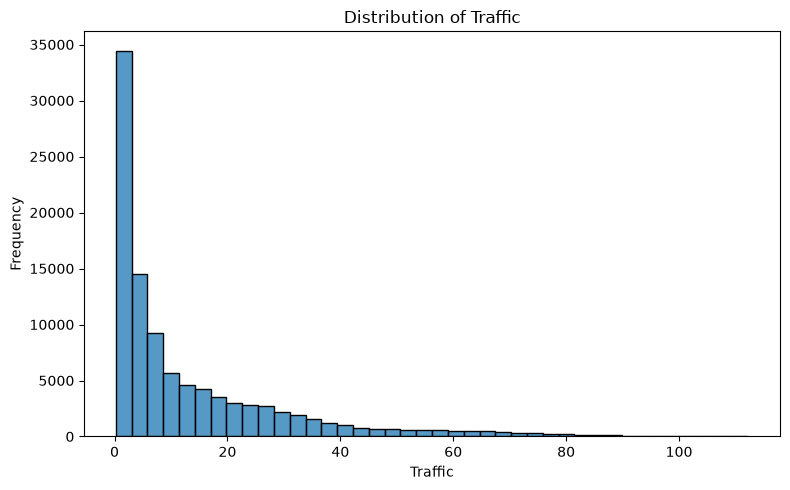

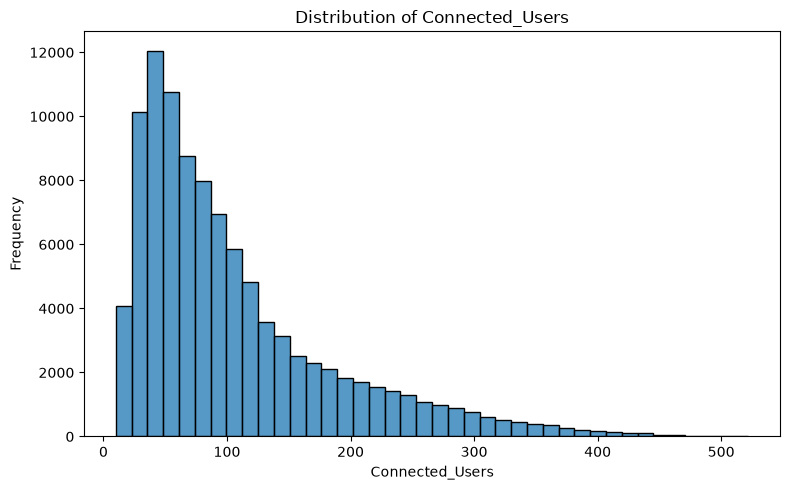

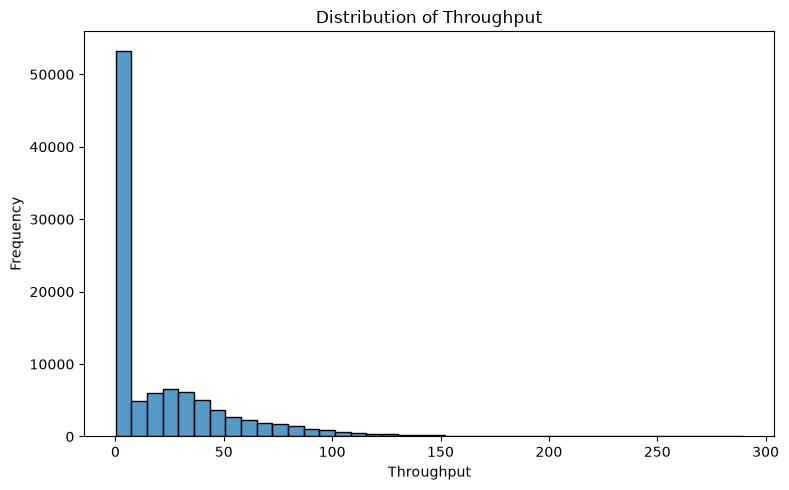

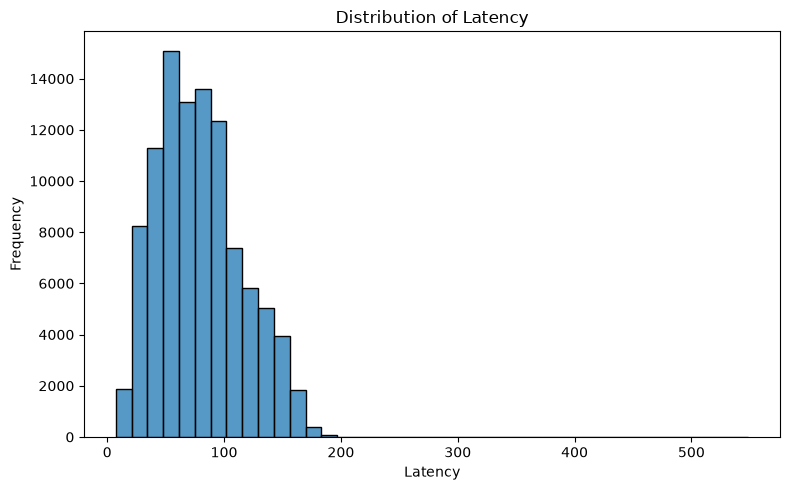

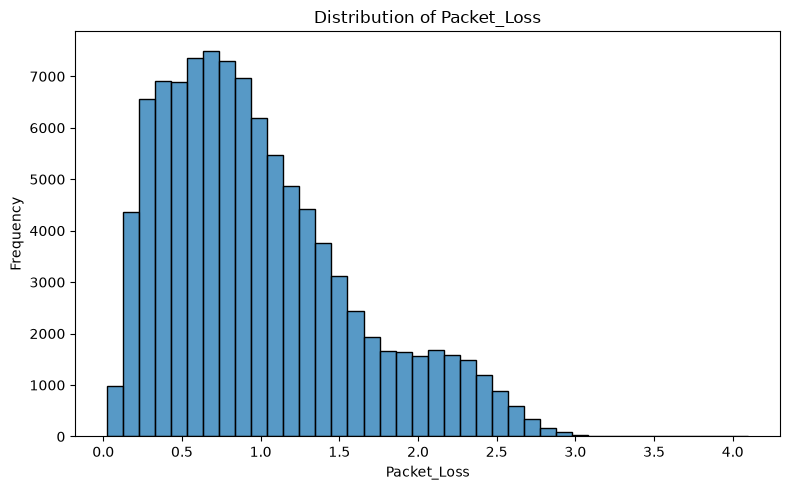

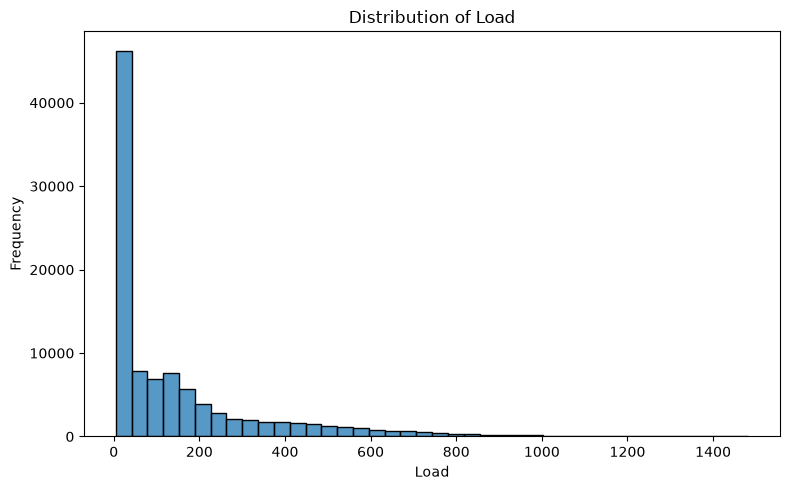

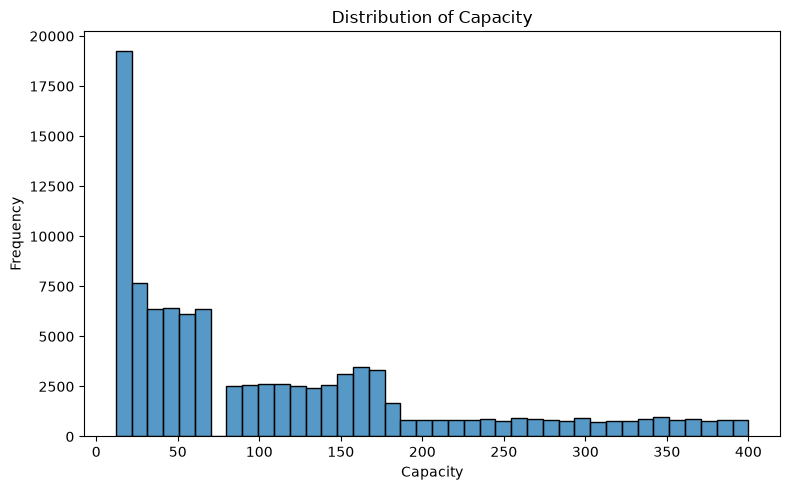

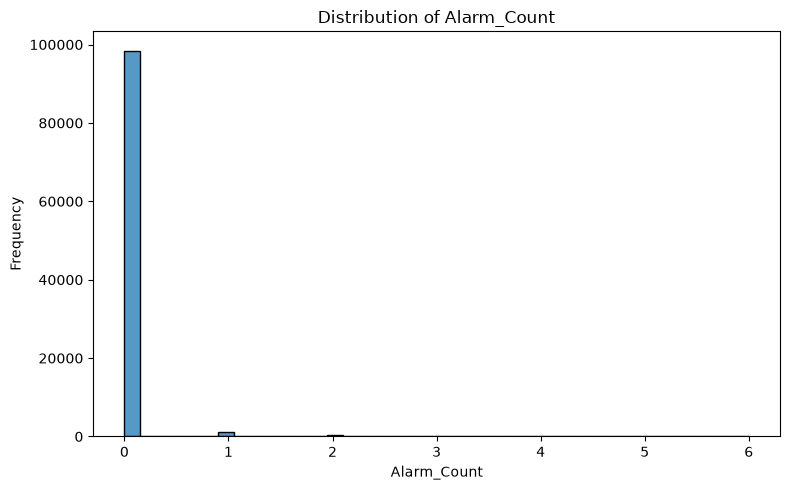

In [14]:

# Distribution plots
plot_cols = [
    "Traffic",
    "Connected_Users",
    "Throughput",
    "Latency",
    "Packet_Loss",
    "Load",
    "Capacity",
    "Alarm_Count"
]

for col in plot_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(kpi_sample[col].dropna(), bins=40)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


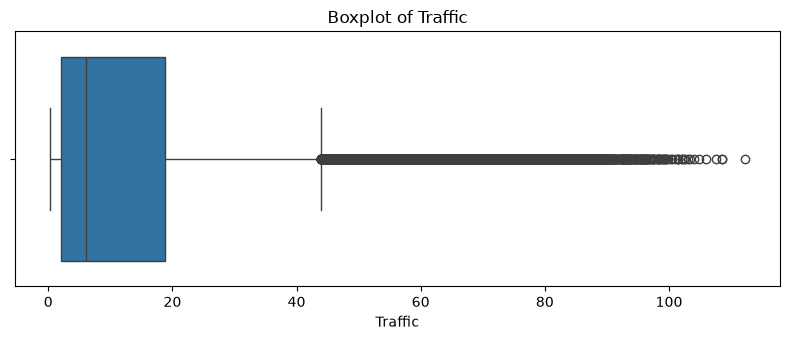

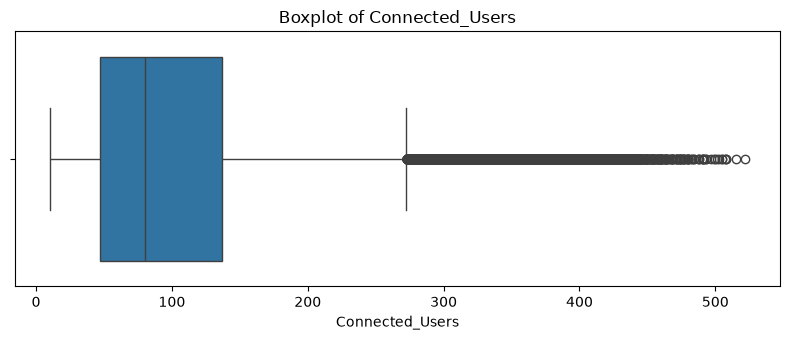

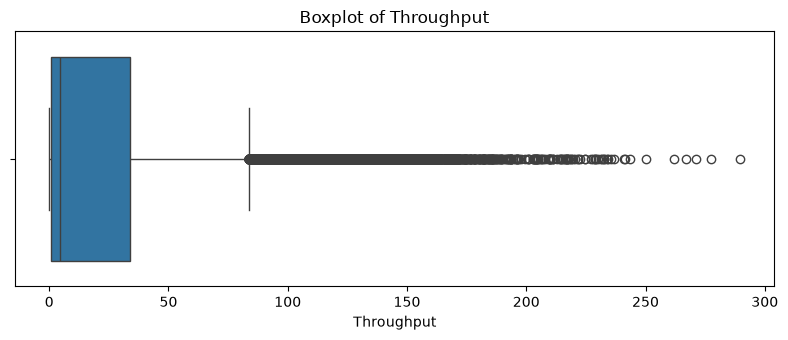

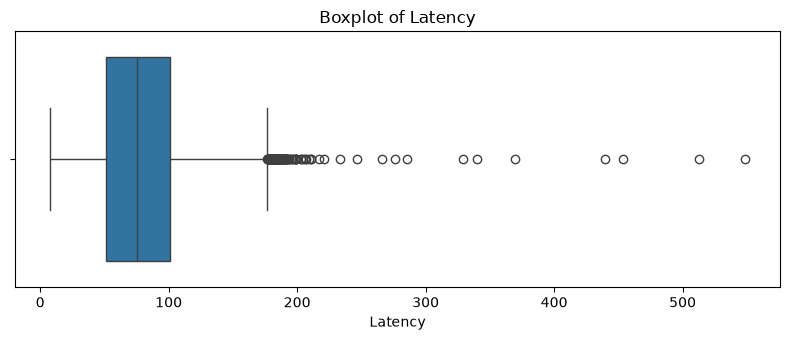

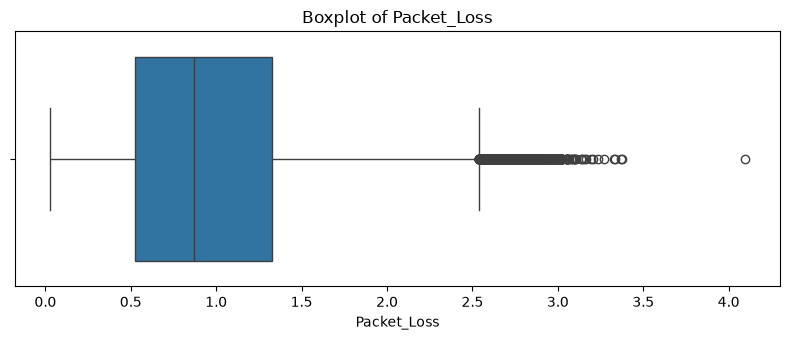

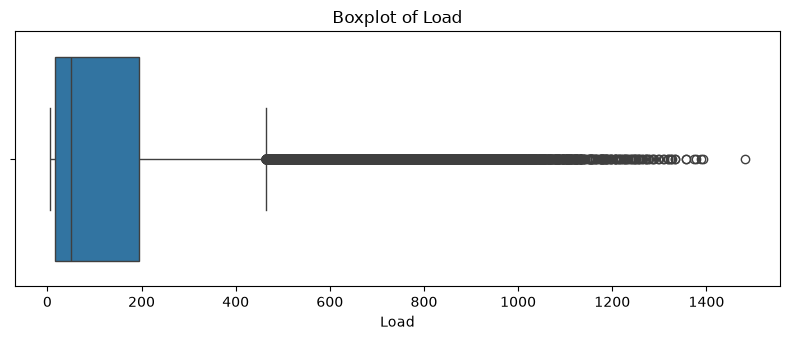

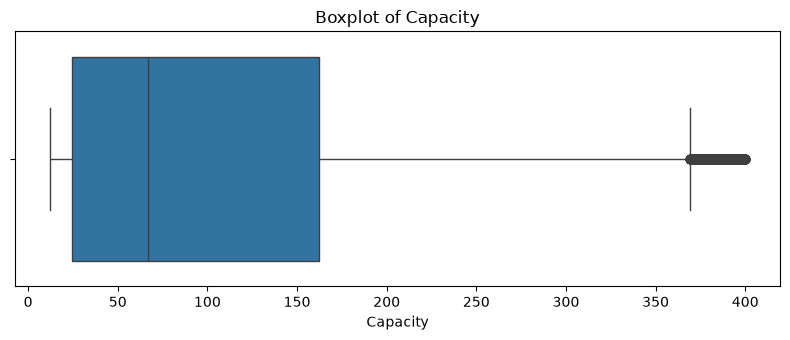

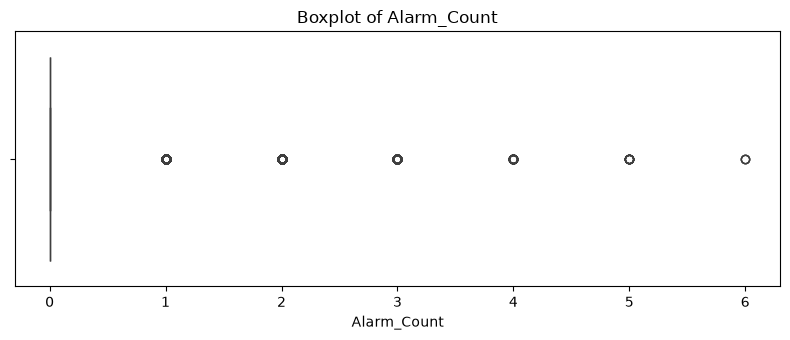

In [15]:

# Boxplots for visual outlier inspection

for col in plot_cols:
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(x=kpi_sample[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


## 6.1 Outlier Summary Using IQR

Boxplots provide a visual check. The table below also counts observations outside the standard IQR fences (Q1 − 1.5×IQR and Q3 + 1.5×IQR). Potential outliers are inspected rather than automatically deleted.

In [16]:
# IQR-based outlier count on the KPI sample

outlier_rows = []

for col in numeric_kpis:

    series = kpi_sample[col].dropna()

    if series.empty:
        continue

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_count = ((series < lower) | (series > upper)).sum()

    outlier_rows.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Fence": lower,
        "Upper_Fence": upper,
        "Outlier_Count": int(outlier_count),
        "Outlier_Percent": round(
            outlier_count / len(series) * 100,
            2
        )
    })

iqr_outlier_table = pd.DataFrame(outlier_rows)

display(iqr_outlier_table)


,Variable,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Outlier_Count,Outlier_Percent
0,Traffic,2.11500,18.83500,16.72000,-22.965000,43.915000,6881,6.88
1,Connected_Users,47.00000,137.00000,90.00000,-88.000000,272.000000,5536,5.54
2,Throughput,0.77100,33.94525,33.17425,-48.990375,83.706625,5264,5.26
3,Latency,51.09775,101.37275,50.27500,-24.314750,176.785250,188,0.19
4,Packet_Loss,0.52400,1.32900,0.80500,-0.683500,2.536500,1464,1.46
5,Load,16.06225,195.22175,179.15950,-252.677000,463.961000,9062,9.06
6,Capacity,24.47800,162.40900,137.93100,-182.418500,369.305500,2532,2.53
7,Alarm_Count,0.00000,0.00000,0.00000,0.000000,0.000000,1551,1.55
8,Previous_Outage_Count,0.00000,0.00000,0.00000,0.000000,0.000000,286,0.29


## 6. Data Distribution and Skewness

In [17]:

# Skewness summary
skewness = (
    kpi_sample[numeric_kpis]
    .skew(numeric_only=True)
    .sort_values(ascending=False)
)

skewness_table = skewness.to_frame("Skewness")

# Simple descriptive interpretation only
skewness_table["Interpretation"] = np.select(
    [
        skewness.abs() < 0.5,
        skewness.abs() < 1.0
    ],
    [
        "Approximately symmetric",
        "Moderately skewed"
    ],
    default="Highly skewed"
)

display(skewness_table)


,Skewness,Interpretation
Previous_Outage_Count,26.082881,Highly skewed
Alarm_Count,12.064879,Highly skewed
Load,2.015425,Highly skewed
Throughput,1.979829,Highly skewed
Traffic,1.978048,Highly skewed
Connected_Users,1.491803,Highly skewed
Capacity,1.153535,Highly skewed
Packet_Loss,0.844591,Moderately skewed
Latency,0.528269,Moderately skewed


## 7. KPI Relationship Analysis

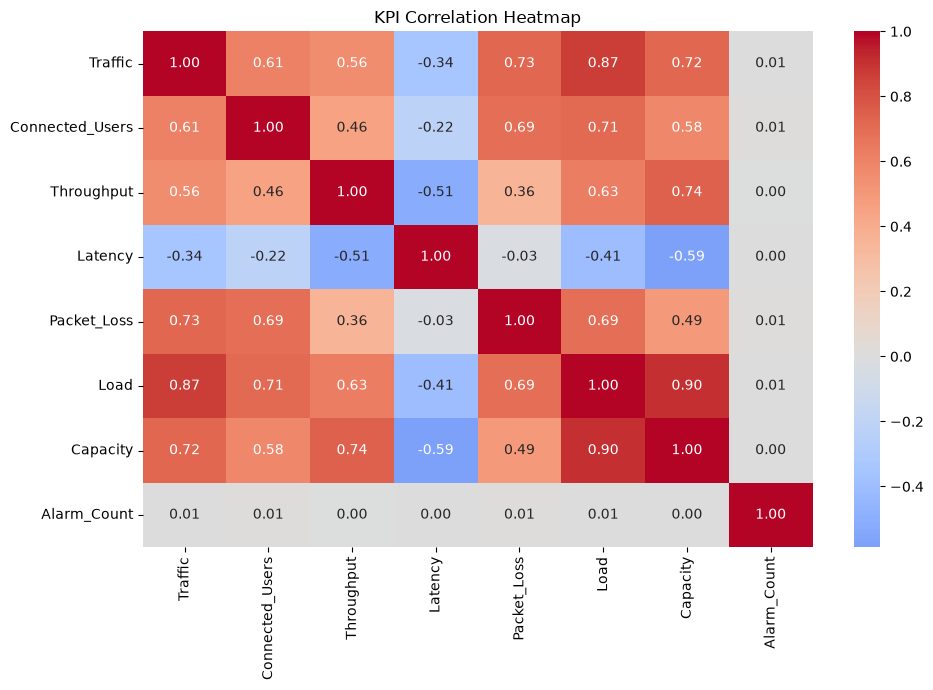

In [18]:

# Correlation heatmap
corr_cols = [
    "Traffic",
    "Connected_Users",
    "Throughput",
    "Latency",
    "Packet_Loss",
    "Load",
    "Capacity",
    "Alarm_Count"
]

corr = kpi_sample[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("KPI Correlation Heatmap")
plt.tight_layout()
plt.show()


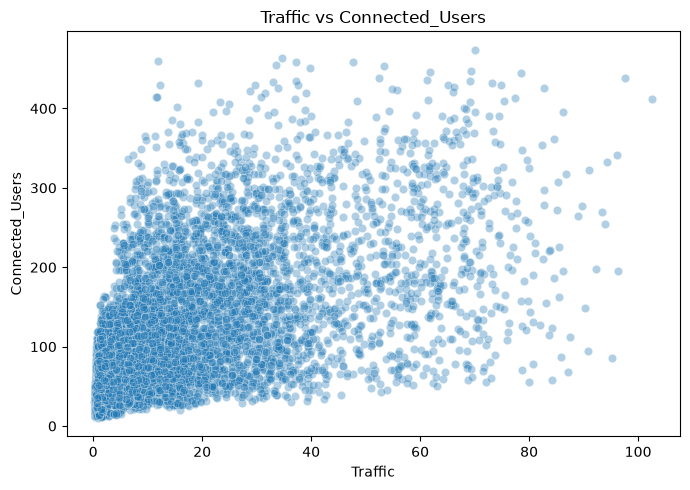

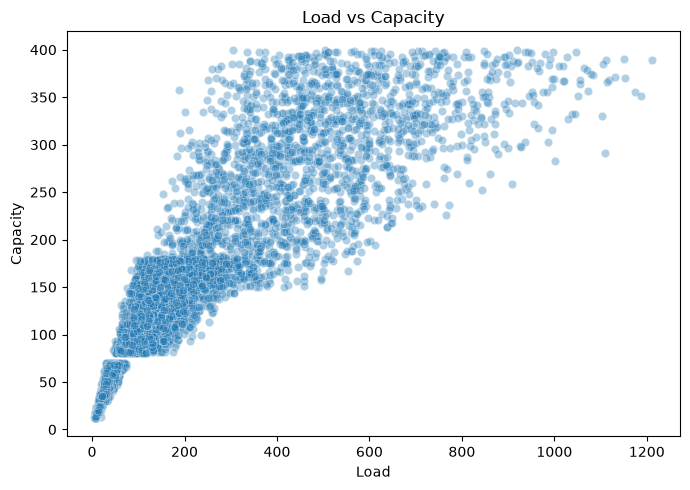

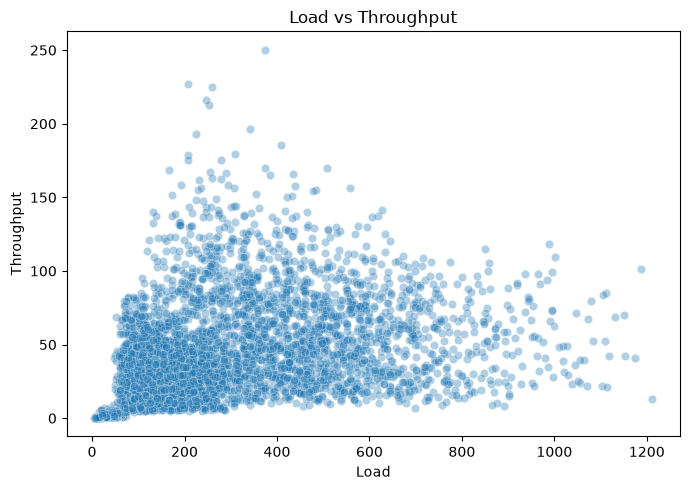

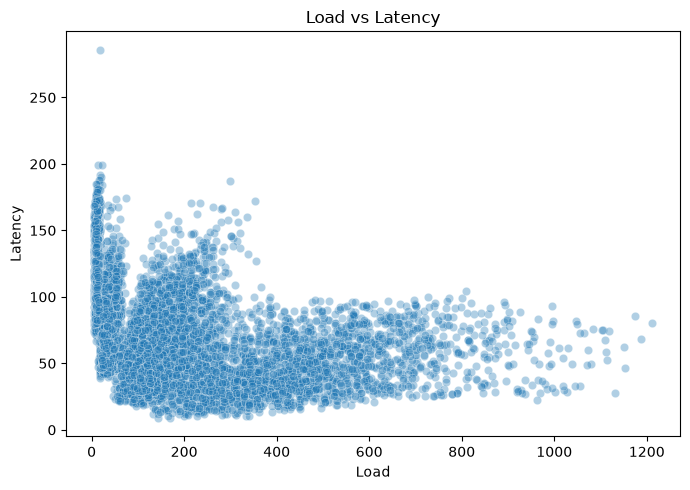

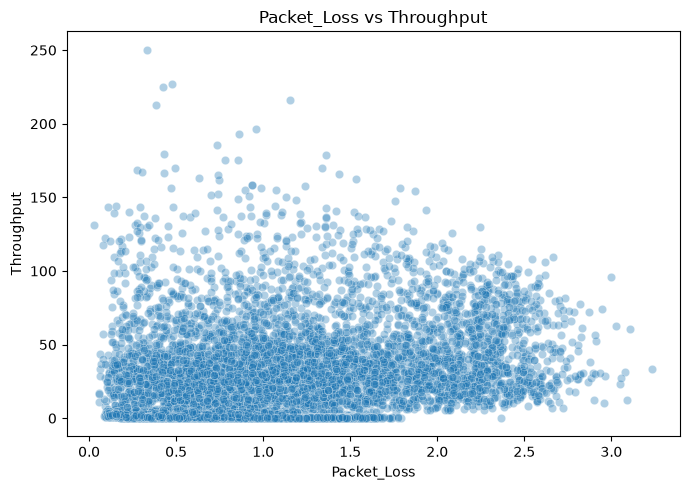

In [19]:

# Selected KPI relationship plots
relationships = [
    ("Traffic", "Connected_Users"),
    ("Load", "Capacity"),
    ("Load", "Throughput"),
    ("Load", "Latency"),
    ("Packet_Loss", "Throughput")
]

for x_col, y_col in relationships:

    plot_df = kpi_sample[[x_col, y_col]].dropna()

    if plot_df.empty:
        continue

    plot_df = plot_df.sample(
        n=min(10_000, len(plot_df)),
        random_state=42
    )

    plt.figure(figsize=(7, 5))
    sns.scatterplot(
        data=plot_df,
        x=x_col,
        y=y_col,
        alpha=0.35
    )

    plt.title(f"{x_col} vs {y_col}")
    plt.tight_layout()
    plt.show()



## 8. Derived Utilization

For this project:

$$
Utilization(\%) = \frac{Load}{Capacity} \times 100
$$

Utilization is derived during data preparation. Here it is calculated on the EDA KPI sample only to understand its distribution.


,Utilization
count,100000.000000
mean,98.684645
std,52.888169
min,36.548060
25%,60.530069
50%,78.487628
75%,123.075869
max,461.586879


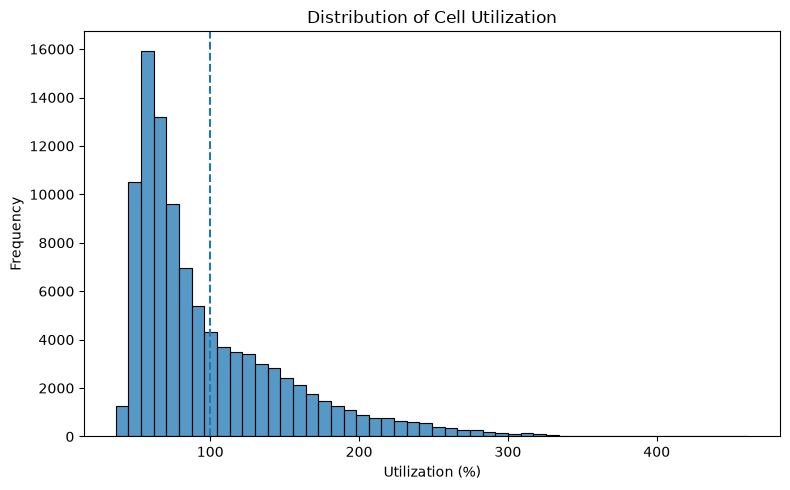

In [20]:

kpi_sample["Utilization"] = (
    kpi_sample["Load"] /
    kpi_sample["Capacity"] *
    100
)

utilization_clean = (
    kpi_sample["Utilization"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

display(
    utilization_clean.describe()
    .to_frame("Utilization")
)

plt.figure(figsize=(8, 5))
sns.histplot(utilization_clean, bins=50)
plt.axvline(100, linestyle="--")
plt.title("Distribution of Cell Utilization")
plt.xlabel("Utilization (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [21]:

# Percentage of sampled KPI rows above 100% utilization

over_100 = (utilization_clean > 100).mean() * 100

print(
    f"Sampled KPI rows with Utilization > 100%: "
    f"{over_100:.2f}%"
)


Sampled KPI rows with Utilization > 100%: 35.05%



## 9. Outage and Recovery Event EDA

`OUTAGE` and `RECOVERY` are treated as event records. We load only these event records for event-level analysis.


In [22]:
# Event-level EDA dataset
# Reuse events_df created during the fast Dataset 2 scan above.

events_df = events_df.copy()

print("Event rows:", f"{len(events_df):,}")
print("Record types:")
display(
    events_df["Record_Type"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

display(events_df.head())


Event rows: 50,674
Record types:


,Count
Record_Type,
OUTAGE,25341
RECOVERY,25333


,Timestamp,Site_ID,Cell_ID,Record_Type,Status,Previous_Outage_Count,Cell_Down_Time,Cell_Up_Time
0,2024-01-01 00:38:33,UG-KIT-4906,UG-KIT-4906-S03,OUTAGE,DOWN,0,2024-01-01 00:38:33,NaT
1,2024-01-01 00:43:07,UG-IGA-4475,UG-IGA-4475-S02,OUTAGE,DOWN,0,2024-01-01 00:43:07,NaT
2,2024-01-01 03:01:32,UG-MBA-2061,UG-MBA-2061-S02,OUTAGE,DOWN,0,2024-01-01 03:01:32,NaT
3,2024-01-01 03:08:07,UG-IGA-4475,UG-IGA-4475-S02,RECOVERY,UP,0,2024-01-01 00:43:07,2024-01-01 03:08:07
4,2024-01-01 03:18:40,UG-NEB-4586,UG-NEB-4586-S03,OUTAGE,DOWN,0,2024-01-01 03:18:40,NaT


In [23]:

# Event counts
display(
    events_df["Record_Type"]
    .value_counts()
    .to_frame("Count")
)


,Count
Record_Type,
OUTAGE,25341
RECOVERY,25333


Total OUTAGE events: 25,341


,Outage_Count
Month,
2024-01,1045
2024-02,957
2024-03,1010
2024-04,984
2024-05,993
2024-06,1109
2024-07,1139
2024-08,1142
2024-09,1085


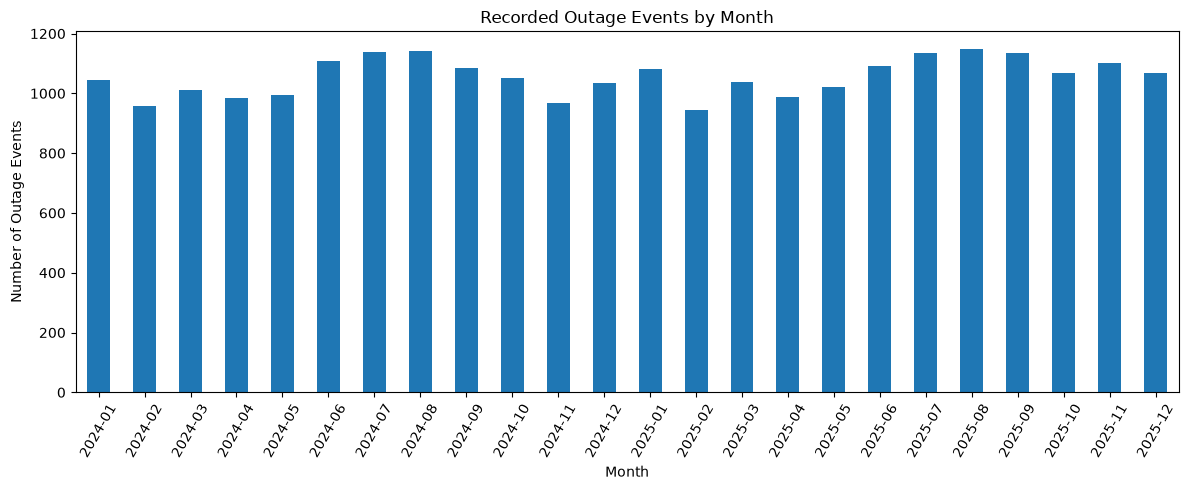

In [24]:

# Outage events only
outages = events_df[
    events_df["Record_Type"] == "OUTAGE"
].copy()

print("Total OUTAGE events:", f"{len(outages):,}")

# Outages per month
outages["Month"] = (
    outages["Cell_Down_Time"]
    .dt.to_period("M")
    .astype(str)
)

monthly_outages = (
    outages["Month"]
    .value_counts()
    .sort_index()
)

display(monthly_outages.to_frame("Outage_Count"))

plt.figure(figsize=(12, 5))
monthly_outages.plot(kind="bar")
plt.title("Recorded Outage Events by Month")
plt.xlabel("Month")
plt.ylabel("Number of Outage Events")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()



## 10. Outage Patterns by Technology and Geography

Dataset 1 provides the technology and geographic context for Dataset 2 event records through `Site_ID + Cell_ID`.


In [25]:

# Add Dataset 1 context to outage events
outage_with_context = outages.merge(
    df1[
        [
            "Site_ID",
            "Cell_ID",
            "Technology",
            "Region",
            "District"
        ]
    ],
    on=["Site_ID", "Cell_ID"],
    how="left",
    validate="many_to_one"
)

print("Outage rows after context join:", len(outage_with_context))

print("\nOutages by technology:")
display(
    outage_with_context["Technology"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nOutages by region:")
display(
    outage_with_context["Region"]
    .value_counts(dropna=False)
    .head(30)
    .to_frame("Count")
)

print("\nOutages by district:")
display(
    outage_with_context["District"]
    .value_counts(dropna=False)
    .head(30)
    .to_frame("Count")
)


Outage rows after context join: 25341

Outages by technology:


,Count
Technology,
2G,7149
3G,6685
4G,6586
5G,4921



Outages by region:


,Count
Region,
Eastern,7164
Western,6350
Northern,6327
Central,5500



Outages by district:


,Count
District,
Mubende,965
Iganga,954
Mukono,941
Mpigi,936
Moyo,934
Fort Portal,931
Yumbe,927
Kitgum,924
Soroti,917


In [26]:

# Cells and sites with the highest number of recorded outages

outages_by_cell = (
    outage_with_context
    .groupby("Cell_ID")
    .size()
    .sort_values(ascending=False)
)

outages_by_site = (
    outage_with_context
    .groupby("Site_ID")
    .size()
    .sort_values(ascending=False)
)

print("Top cells by outage count:")
display(outages_by_cell.head(20).to_frame("Outage_Count"))

print("Top sites by outage count:")
display(outages_by_site.head(20).to_frame("Outage_Count"))


Top cells by outage count:


,Outage_Count
Cell_ID,
UG-SOR-4634-S02,7
UG-LIR-5887-S01,7
UG-KML-5725-S01,7
UG-IGA-5154-S04,7
UG-NEB-4803-S02,6
UG-YUM-4990-S03,6
UG-NEB-5186-S04,6
UG-MSK-4696-S03,6
UG-ARU-2598-S01,6


Top sites by outage count:


,Outage_Count
Site_ID,
UG-MBA-1466,15
UG-GUL-0708,14
UG-MPG-2422,12
UG-NEB-5186,12
UG-ARU-2598,12
UG-HOI-2289,12
UG-HOI-4710,12
UG-GUL-4503,12
UG-BUS-2259,12



## 11. Outage Duration EDA

`Outage_Duration` is **not a raw Dataset 2 column**. It is calculated from `Cell_Down_Time` and `Cell_Up_Time`.

For this EDA, each outage is matched to the next recovery event for the same `Cell_ID`. Only recovered outages with a valid non-negative duration are used.


In [27]:

# Prepare outage and recovery timestamps

outage_times = (
    events_df.loc[
        events_df["Record_Type"] == "OUTAGE",
        ["Cell_ID", "Cell_Down_Time"]
    ]
    .dropna()
    .sort_values(["Cell_Down_Time", "Cell_ID"])
    .reset_index(drop=True)
)

recovery_times = (
    events_df.loc[
        events_df["Record_Type"] == "RECOVERY",
        ["Cell_ID", "Cell_Up_Time"]
    ]
    .dropna()
    .sort_values(["Cell_Up_Time", "Cell_ID"])
    .reset_index(drop=True)
)

print("Outage events:", len(outage_times))
print("Recovery events:", len(recovery_times))


Outage events: 25341
Recovery events: 25333


In [28]:

# Match each outage to the next recovery event for the same cell
duration_df = pd.merge_asof(
    outage_times,
    recovery_times,
    by="Cell_ID",
    left_on="Cell_Down_Time",
    right_on="Cell_Up_Time",
    direction="forward",
    allow_exact_matches=True
)

duration_df["Outage_Duration_Hours"] = (
    duration_df["Cell_Up_Time"] -
    duration_df["Cell_Down_Time"]
).dt.total_seconds() / 3600

duration_df = duration_df[
    duration_df["Cell_Up_Time"].notna()
    & (duration_df["Outage_Duration_Hours"] >= 0)
].copy()

print(
    "Recovered outage events with valid duration:",
    f"{len(duration_df):,}"
)

display(
    duration_df["Outage_Duration_Hours"]
    .describe()
    .to_frame("Duration_Hours")
)


Recovered outage events with valid duration: 25,333


,Duration_Hours
count,25333.000000
mean,2.242161
std,1.017604
min,0.500000
25%,1.366667
50%,2.233333
75%,3.133333
max,4.000000


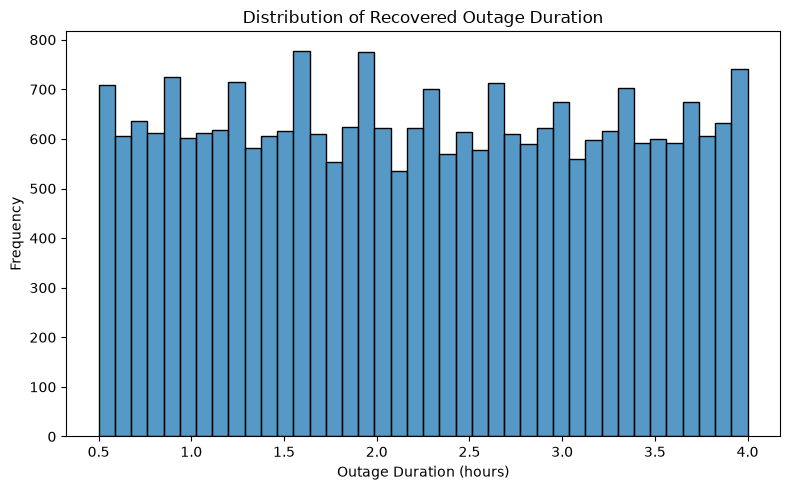

In [29]:

# Outage duration distribution

if not duration_df.empty:
    plt.figure(figsize=(8, 5))
    sns.histplot(
        duration_df["Outage_Duration_Hours"],
        bins=40
    )
    plt.title("Distribution of Recovered Outage Duration")
    plt.xlabel("Outage Duration (hours)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("No recovered outages with valid duration were available for this analysis.")



## 12. Project-Defined Seasonal EDA

The project uses these **project-defined seasonal periods**:

- **Summer:** February–May
- **Rainy Season:** June–September
- **Winter:** October–January

These labels are used for this project's analysis and later seasonal test design.


,Outage_Count
Season,
Summer,7937
Rainy Season,8986
Winter,8418


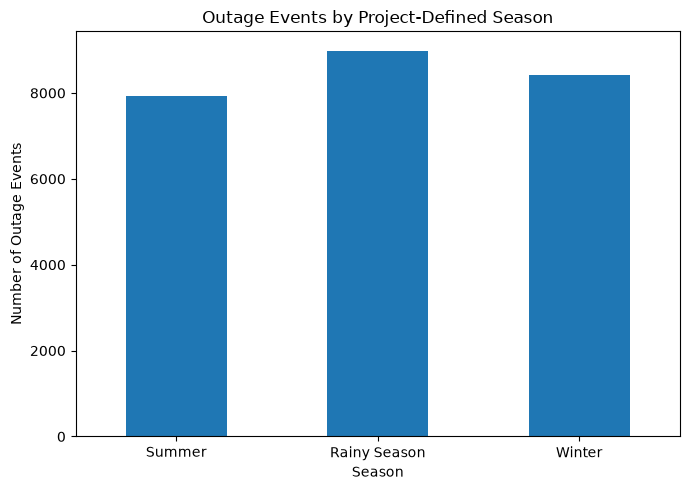

In [30]:

def project_season(month):
    if month in [2, 3, 4, 5]:
        return "Summer"
    if month in [6, 7, 8, 9]:
        return "Rainy Season"
    return "Winter"

outage_with_context["Season"] = (
    outage_with_context["Cell_Down_Time"]
    .dt.month
    .apply(project_season)
)

season_order = [
    "Summer",
    "Rainy Season",
    "Winter"
]

season_counts = (
    outage_with_context["Season"]
    .value_counts()
    .reindex(season_order, fill_value=0)
)

display(
    season_counts.to_frame("Outage_Count")
)

plt.figure(figsize=(7, 5))
season_counts.plot(kind="bar")
plt.title("Outage Events by Project-Defined Season")
plt.xlabel("Season")
plt.ylabel("Number of Outage Events")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



## 13. Dataset Relationship Check

Dataset 1 is the network-structure source, while Dataset 2 contains time-based network behavior and events. They are combined conceptually and later in data preparation using `Site_ID + Cell_ID`.

This section checks that Dataset 2 event records can be matched to Dataset 1.


In [31]:

# Coverage of Dataset 2 event cells in Dataset 1

event_cells = set(events_df["Cell_ID"].dropna().astype(str))
master_cells = set(df1["Cell_ID"].dropna().astype(str))

matched = len(event_cells & master_cells)
unmatched = len(event_cells - master_cells)

print("Unique event cells:", f"{len(event_cells):,}")
print("Matched to Dataset 1:", f"{matched:,}")
print("Unmatched:", f"{unmatched:,}")

if len(event_cells) > 0:
    print(
        "Match rate:",
        f"{matched / len(event_cells) * 100:.2f}%"
    )


Unique event cells: 15,363
Matched to Dataset 1: 15,363
Unmatched: 0
Match rate: 100.00%



## 14. EDA Summary Checklist

After running the notebook, use the actual outputs to document:

**Dataset 1**
- Total sites and cells
- Technology distribution
- Region and district distribution
- Cells per site
- Neighbor count distribution
- Missing values and duplicates

**Dataset 2**
- Total rows and time range
- Number of unique sites and cells
- `KPI / OUTAGE / RECOVERY` counts
- Status distribution
- Missing-value pattern by record type
- KPI descriptive statistics
- KPI distributions, skewness, and outliers
- KPI relationships and correlations
- Utilization distribution
- Outage counts by month, technology, region, district, site, and cell
- Recovered outage duration
- Project-defined seasonal patterns
- Dataset 1 ↔ Dataset 2 matching coverage

### Important boundary for the next stage

This notebook is **EDA only**.

The following steps come later:

**Data Preparation → Feature Engineering (previous 6 hours) → Leakage Check → Target Creation (`Outage_Next_12h`) → Chronological / unseen-site evaluation → Model Training → Model Evaluation.**

The following future 12-hour information must not be used as predictor features.
